In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
sys.path.append('../../')
from helper_function import *
import gc
import pandas as pd
from scipy.sparse import load_npz

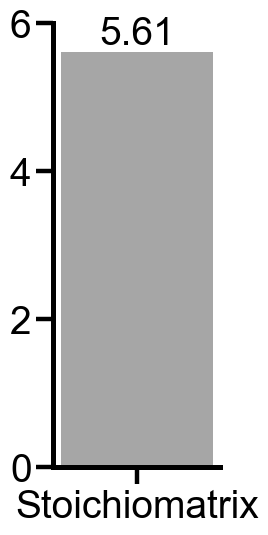

In [2]:
set_panel_style(scale=4)

data_list = [5.61]
labels = ["Stoichiomatrix"]

means, stds = [], []
for item in data_list:
    if isinstance(item, (list, np.ndarray)):
        arr = np.asarray(item, dtype=float)
        arr = arr[np.isfinite(arr)]
        means.append(float(np.mean(arr)))
        stds.append(float(np.std(arr)))
    else:
        means.append(float(item))
        stds.append(0.0)

stoich_gray = (0.65, 0.65, 0.65)
black = (0.0, 0.0, 0.0)
bar_colors = [stoich_gray]

fig, ax = plt.subplots(figsize=(3, 6))
x = np.arange(len(labels))

bars = ax.bar(
    x, means,
    capsize=5,
    color=bar_colors,
    edgecolor="none",
    alpha=1
)

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=0, ha="center")
# ax.set_ylabel("RMS Divergence")
ax.set_ylim(0, 6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h,
        f"{h:.2f}",
        ha="center", va="bottom"
    )

plt.tight_layout()
# fig.savefig("Figure5A.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()

In [3]:
def parse_array(s):
    if isinstance(s, np.ndarray):
        return s
    if isinstance(s, list):
        return np.array(s)
    
    if pd.isna(s):
        return np.array([])

    s = str(s).strip()

    if s.startswith('[') and s.endswith(']'):
        s = s[1:-1]

    return np.fromstring(s, sep=' ')

df = pd.read_csv(
    'flux_flow_graph_comparision_across_entropy_ei_new.csv',
    converters={
        'Gini': parse_array,
        'Entropy': parse_array,
        'E': parse_array
    }
)

df_nonzero = df[df["lambda"] != 0].copy()

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def compute_env_rms_E(df_nonzero, M_value, env_value):
    sub20 = df_nonzero[
        (df_nonzero["M"] == 20) &
        (df_nonzero["Env_index"] == env_value) &
        (df_nonzero["lambda"] > 0)
    ]

    valid_species = set(sub20["Species_index"].unique())

    if len(valid_species) < 2:
        return np.nan

    sub = df_nonzero[
        (df_nonzero["M"] == M_value) &
        (df_nonzero["Env_index"] == env_value) &
        (df_nonzero["Species_index"].isin(valid_species))
    ]

    E = np.vstack(sub["E"].values)

    center = E.mean(axis=0)

    rms_radius = np.sqrt(((E - center)**2).sum(axis=1).mean())
    return rms_radius

env_list = sorted(df_nonzero["Env_index"].unique())

rmsE_20 = []
rmsE_400 = []

for env in env_list:
    r20 = compute_env_rms_E(df_nonzero, M_value=20, env_value=env)
    r400 = compute_env_rms_E(df_nonzero, M_value=400, env_value=env)
    rmsE_20.append(r20)
    rmsE_400.append(r400)

rmsE_20 = [x for x in rmsE_20 if not np.isnan(x)]
rmsE_400 = [x for x in rmsE_400 if not np.isnan(x)]

rmsE_20 = np.array(rmsE_20) / np.sqrt(20)
rmsE_400 = np.array(rmsE_400) / np.sqrt(20)

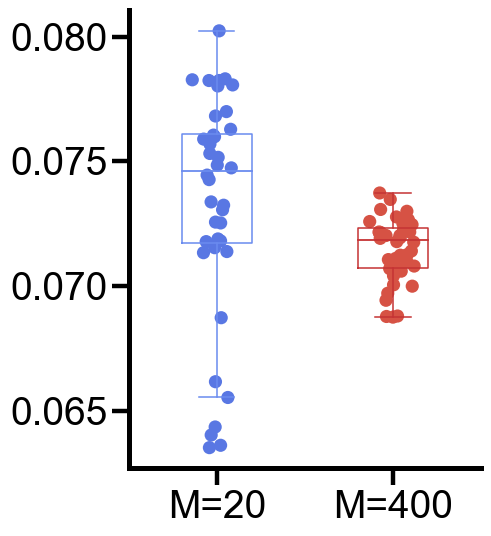

In [5]:
import matplotlib.ticker as ticker

cmap = plt.get_cmap("coolwarm")
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

complex_line_color    = colors[19]
complex_scatter_color = colors[18]
simple_line_color     = colors[3]
simple_scatter_color  = colors[2]

fig, ax = plt.subplots(figsize=(6, 6))

data = [rmsE_20, rmsE_400]
labels = ["M=20", "M=400"]
positions = [1, 2] 

bp = ax.boxplot(
    data,
    positions=positions,
    widths=0.4,
    showfliers=False,
    patch_artist=False,
    boxprops=dict(linewidth=1.1),
    whiskerprops=dict(linewidth=1.1),
    capprops=dict(linewidth=1.1),
    medianprops=dict(linewidth=1.3),
)

group_line_colors = [simple_line_color, complex_line_color]

for box, c in zip(bp["boxes"], group_line_colors):
    box.set_color(c)

for med, c in zip(bp["medians"], group_line_colors):
    med.set_color(c)

for gi, c in enumerate(group_line_colors):
    bp["whiskers"][2*gi].set_color(c)
    bp["whiskers"][2*gi + 1].set_color(c)
    bp["caps"][2*gi].set_color(c)
    bp["caps"][2*gi + 1].set_color(c)

# ---- jittered scatter (alpha=1) ----
rng = np.random.default_rng(0)
j1 = positions[0] + rng.normal(0, 0.06, size=len(rmsE_20))
j2 = positions[1] + rng.normal(0, 0.06, size=len(rmsE_400))

ax.scatter(j1, rmsE_20,  s=90, color=simple_scatter_color, alpha=1, edgecolors="none")
ax.scatter(j2, rmsE_400, s=90, color=complex_scatter_color, alpha=1, edgecolors="none")

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:.3f}'))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.subplots_adjust(left=0.1, right=0.2)

plt.tight_layout()
# fig.savefig("Figure5B.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()


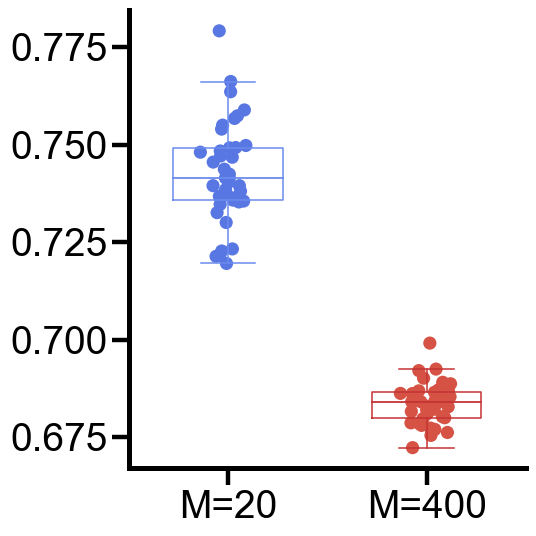

In [6]:
def compute_env_rms_entropy(df_nonzero, M_value, env_value):
    sub20 = df_nonzero[
        (df_nonzero["M"] == 20) &
        (df_nonzero["Env_index"] == env_value) &
        (df_nonzero["lambda"] > 0)
    ]

    valid_species = set(sub20["Species_index"].unique())

    if len(valid_species) < 2:
        return np.nan

    sub = df_nonzero[
        (df_nonzero["M"] == M_value) &
        (df_nonzero["Env_index"] == env_value) &
        (df_nonzero["Species_index"].isin(valid_species))
    ]

    E = np.vstack(sub["Entropy"].values)
    center = E.mean(axis=0)

    return np.sqrt(((E - center) ** 2).sum(axis=1).mean())


env_list = sorted(df_nonzero["Env_index"].unique())

rmsEntropy_20 = []
rmsEntropy_400 = []

for env in env_list:
    rmsEntropy_20.append(
        compute_env_rms_entropy(df_nonzero, M_value=20, env_value=env)
    )
    rmsEntropy_400.append(
        compute_env_rms_entropy(df_nonzero, M_value=400, env_value=env)
    )

rmsEntropy_20 = np.array(
    [x for x in rmsEntropy_20 if not np.isnan(x)]
) / np.sqrt(20)

rmsEntropy_400 = np.array(
    [x for x in rmsEntropy_400 if not np.isnan(x)]
) / np.sqrt(20)

cmap = plt.get_cmap("coolwarm")
colors = [cmap(i / 20) for i in range(20)]

simple_line_color = colors[3]
simple_scatter_color = colors[2]
complex_line_color = colors[19]
complex_scatter_color = colors[18]

fig, ax = plt.subplots(figsize=(6, 6))

data = [rmsEntropy_20, rmsEntropy_400]
labels = ["M=20", "M=400"]
positions = [1, 2]

bp = ax.boxplot(
    data,
    positions=positions,
    widths=0.55,
    showfliers=False,
    patch_artist=False,
    boxprops=dict(linewidth=1.1),
    whiskerprops=dict(linewidth=1.1),
    capprops=dict(linewidth=1.1),
    medianprops=dict(linewidth=1.3),
)

group_colors = [simple_line_color, complex_line_color]

for box, c in zip(bp["boxes"], group_colors):
    box.set_color(c)

for median, c in zip(bp["medians"], group_colors):
    median.set_color(c)

for i, c in enumerate(group_colors):
    for key in ["whiskers", "caps"]:
        bp[key][2 * i].set_color(c)
        bp[key][2 * i + 1].set_color(c)

rng = np.random.default_rng(0)

j1 = positions[0] + rng.normal(0, 0.06, len(rmsEntropy_20))
j2 = positions[1] + rng.normal(0, 0.06, len(rmsEntropy_400))

ax.scatter(
    j1, rmsEntropy_20,
    s=90,
    color=simple_scatter_color,
    edgecolors="none"
)

ax.scatter(
    j2, rmsEntropy_400,
    s=90,
    color=complex_scatter_color,
    edgecolors="none"
)

ax.set_xticks(positions)
ax.set_xticklabels(labels)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
# fig.savefig("Figure5C.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()

In [ ]:
K = 20 
dfH = df_nonzero[df_nonzero["lambda"] > 0].copy()

dfH["H_norm"] = dfH["Entropy"] / np.log(K)


summary_M = (
    dfH.groupby("M")
       .agg(mean_H=("Entropy","mean"),
            mean_Hnorm=("H_norm","mean"))
       .reset_index()
)

summary_sp_M = (
    dfH.groupby(["Species_index", "M"])
       .agg(mean_H=("Entropy","mean"),
            mean_Hnorm=("H_norm","mean"),
            mean_E = ("E","mean"),
            n_env=("Env_index","nunique"))
       .reset_index()
)

wide = summary_sp_M.pivot(index="Species_index", columns="M", values="mean_H")
wide = wide.rename(columns={20: "Hnorm_simple", 400: "Hnorm_complex"})

wide["delta_Hnorm"] = wide["Hnorm_complex"] - wide["Hnorm_simple"]  
wide["delta_C"]     = (1 - wide["Hnorm_complex"]) - (1 - wide["Hnorm_simple"])  # = -delta_Hnorm

wide = wide.reset_index()

delta_mat = np.vstack(wide["delta_Hnorm"].apply(lambda v: np.asarray(v, float)).values)
df_long = pd.DataFrame({
    "Species_index": np.repeat(wide["Species_index"].values, K),
    "sector_idx":    np.tile(np.arange(K), len(wide)),
    "delta_Hnorm":   delta_mat.reshape(-1),
})


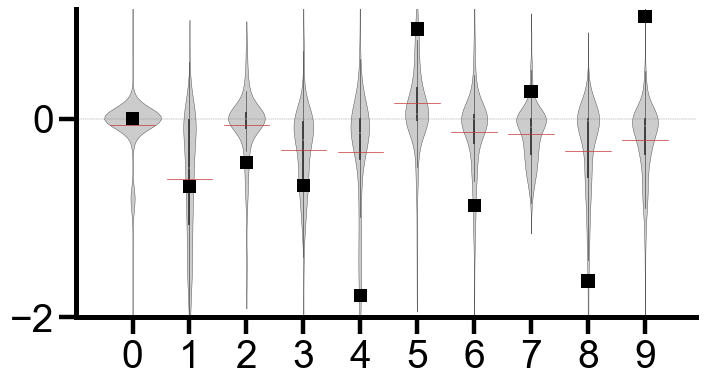

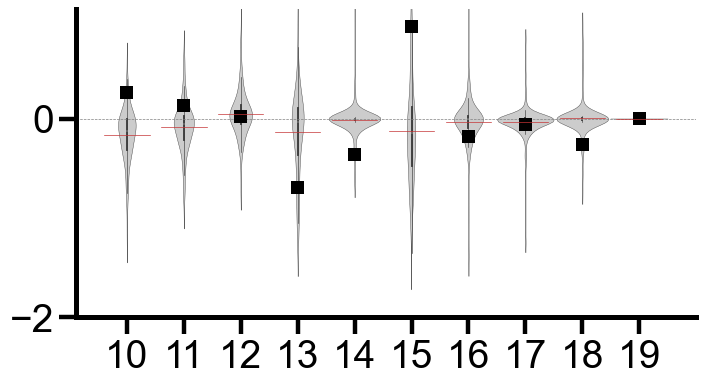

In [ ]:
sp_id = 51
visualed_K = 20

line_color = colors[19]

data = [
    df_long.loc[df_long["sector_idx"] == i, "delta_Hnorm"].dropna().values
    for i in range(visualed_K)
]

fig, ax1 = plt.subplots(figsize=(8, 4))

sns.violinplot(
    data=data[:10],
    ax=ax1,
    orient="v",
    linewidth=0.3,
    width=1.0,
    color=(0.8, 0.8, 0.8)
)

mean_values_1 = [np.mean(d) for d in data[:10]]
for i, mean in enumerate(mean_values_1):
    ax1.plot([i - 0.4, i + 0.4], [mean, mean], color=line_color, linewidth=0.5, zorder=5)

sp_1 = df_long[df_long["Species_index"] == sp_id].set_index("sector_idx")["delta_Hnorm"]
xs_1 = np.arange(10)
ys_1 = np.array([sp_1.get(i, np.nan) for i in range(10)], dtype=float)

mask_1 = np.isfinite(ys_1)
ax1.scatter(
    xs_1[mask_1],ys_1[mask_1], 
    s=90,
    color="black", 
    edgecolors="none",
    marker="s",
    alpha=1,
    zorder=3
)

ax1.set_xticks(range(10))
ax1.set_xticklabels([str(i) for i in range(10)])

# 0 参考线
ax1.axhline(0, linestyle="--", color="gray", linewidth=0.3)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.set_ylim(-2.0, 1.1)

# fig.savefig("Figure5D_1.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
#plt.tight_layout()


fig, ax2 = plt.subplots(figsize=(8, 4))

sns.violinplot(
    data=data[10:],
    ax=ax2,
    orient="v",
    linewidth=0.3,
    width=1.0,  
    color=(0.8, 0.8, 0.8)
)

mean_values_2 = [np.mean(d) for d in data[10:]]
for i, mean in enumerate(mean_values_2):
    ax2.plot([i - 0.4, i + 0.4], [mean, mean], color=line_color, linewidth=0.5, zorder=5)

sp_2 = df_long[df_long["Species_index"] == sp_id].set_index("sector_idx")["delta_Hnorm"]
xs_2 = np.arange(10, 20) - 10
ys_2 = np.array([sp_2.get(i, np.nan) for i in range(10, 20)], dtype=float)

mask_2 = np.isfinite(ys_2)
ax2.scatter(
    xs_2[mask_2], ys_2[mask_2],
    s=90, 
    color="black",
    edgecolors="none",
    marker="s",
    alpha=1,
    zorder=3 
)

ax2.set_xticks(range(10))
ax2.set_xticklabels([str(i) for i in range(10, 20)])
ax2.set_ylim(-2.0, 1.1)

ax2.axhline(0, linestyle="--", color="gray", linewidth=0.5)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

#plt.tight_layout()
# fig.savefig("Figure5D_2.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)

# 显示两个图
plt.show()
